In [3]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
from scipy.io import mmread
import helper

# Figure 3

In [2]:
adata_hao = anndata.read_h5ad('../data/hao_adata.h5ad')
adata_hao.obs.value_counts()
bulks_fino = pd.read_csv("../data/bulks_finotello_tpm.csv", index_col=0)


In [3]:
# for 1000, 5000,10000,50000, 100000, all cells make subsets with the same percentage of each cell type
def _sample(adata: AnnData, size: int, run=0) -> AnnData:
    np.random.seed(run)
    annotations = adata.obs['cell_type']
    annotation_counts = annotations.value_counts()
    selected_cells = []
    # makes sure that each cell type is represented  but keep the proportions
    for annotation in annotation_counts.index:
        cells = annotations[annotations == annotation].index
        n_select = max(1, int(size * (len(cells) / len(annotations))))
        cells = np.random.choice(cells, min(n_select, len(cells)), replace=False)
        selected_cells.extend(cells)
    # if we have less cells than size, we randomly add cells
    while len(selected_cells) < size:
        cell = np.random.choice(annotations.index, 1, replace=False)[0]
        if cell not in selected_cells:
            selected_cells.append(cell)
    return adata[selected_cells, :]
# python
import psutil, threading, time, gc

MB = 1024 * 1024

class PeakRSS:
    def __init__(self, include_children=True, interval=0.01):
        self.proc = psutil.Process()
        self.include_children = include_children
        self.interval = interval
        self.max_rss = 0
        self._stop = threading.Event()
        self._t = None

    def _rss_now(self):
        rss = 0
        try:
            rss += self.proc.memory_info().rss
        except psutil.Error:
            pass
        if self.include_children:
            for c in self.proc.children(recursive=True):
                try:
                    rss += c.memory_info().rss
                except psutil.Error:
                    pass
        return rss

    def start(self):
        self.max_rss = 0
        self._stop.clear()
        self._t = threading.Thread(target=self._run, daemon=True)
        self._t.start()

    def _run(self):
        while not self._stop.is_set():
            self.max_rss = max(self.max_rss, self._rss_now())
            time.sleep(self.interval)

    def stop(self):
        self._stop.set()
        if self._t:
            self._t.join()


In [17]:
import time
import psutil
import pandas as pd
import numpy as np

# subset sizes (include full dataset size)
subset_sizes = [1000, 5000, 10000,25000, 50000, 100000, adata_hao.shape[0]]

n_runs = 5
runtime_records = []
memory_records = []

proc = psutil.Process()

# use the finotello bulks but only the first 5 samples
bulks_fino_5 = bulks_fino.iloc[:, :5]

for n_cells in subset_sizes:
    # create subset on-the-fly (use full adata for the largest entry)
    if n_cells == adata_hao.shape[0]:
        ad = adata_hao
    else:
        ad = _sample(adata_hao, int(n_cells), run=0)

    for run in range(n_runs):
        # use the real finotello bulks with 5 samples
        # ensure genes match: if necessary subset or align
        genes = ad.var_names if hasattr(ad, "var_names") else ad.var.index
        # align bulks to genes present in ad (subset columns remain the same)
        bulks_for_run = bulks_fino_5.reindex(genes).fillna(0)

        # brief pause to stabilise measurements
        gc.collect()
        time.sleep(0.2)
        baseline_rss = PeakRSS(include_children=True)._rss_now()

        sampler = PeakRSS(include_children=True, interval=0.01)
        sampler.start()
        t0 = time.perf_counter()
        try:
            _est, _sig = rp.rectangle(ad, bulks_for_run.T)
        except Exception:
            _est = None
        t1 = time.perf_counter()
        sampler.stop()

        elapsed_s = t1 - t0
        peak_diff_mb = max(0.0, (sampler.max_rss - baseline_rss) / MB)

        runtime_records.append({"n_cells": int(n_cells), "run": run + 1, "time": elapsed_s})
        memory_records.append({"n_cells": int(n_cells), "run": run + 1, "memory": peak_diff_mb})

# save raw records
runtime_df = pd.DataFrame(runtime_records)
memory_df = pd.DataFrame(memory_records)

runtime_df.to_csv('../data/fig3/rectangle_runtime.csv')
memory_df.to_csv('../data/fig3/rectangle_memory.csv')

# compute and save summary (mean and std)
runtime_summary = runtime_df.groupby('n_cells')['time'].agg(['mean', 'std']).reset_index().rename(columns={'mean':'time_mean','std':'time_sd'})
memory_summary = memory_df.groupby('n_cells')['memory'].agg(['mean', 'std']).reset_index().rename(columns={'mean':'memory_mean','std':'memory_sd'})

runtime_summary.to_csv('../data/fig3/rectangle_runtime_summary.csv', index=False)
memory_summary.to_csv('../data/fig3/rectangle_memory_summary.csv', index=False)

print("Benchmarking finished. Raw and summary CSVs written to ../data/fig3/")

2025-10-16 20:32:17.403 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:330 - Using 18425 common genes between bulks and single-cell data
2025-10-16 20:32:18.182 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2025-10-16 20:32:24.210 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2025-10-16 20:32:32.138 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for ILC
2025-10-16 20:32:34.049 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Monocytes
2025-10-16 20:32:35.684 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2025-10-16 20:32:36.813 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Plasma cells
2025-10-16 20:32:37.708 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Platelet
2025-10-16

duplicated markers:  ['AC020656.1', 'ASAH1', 'CD86', 'CFP', 'CLEC4A', 'CPVL', 'CSTA', 'ETS2', 'ASAH1', 'AC020656.1', 'CD86', 'CFP', 'CLEC4A', 'CPVL', 'CSTA', 'ETS2']


2025-10-16 20:32:44.591 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:225 - Optimal condition number: 79
2025-10-16 20:32:44.797 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:419 - RMSE:0.05196882874132246, Pearson R:0.6994573358416994 for p=0.05, lfc=1.7


duplicated markers:  ['AC020656.1', 'CD86', 'CFP', 'CLEC4A', 'CSTA', 'ETS2', 'AC020656.1', 'CD86', 'CFP', 'CLEC4A', 'CSTA', 'ETS2']


2025-10-16 20:32:44.937 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:225 - Optimal condition number: 79
2025-10-16 20:32:45.146 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:419 - RMSE:0.05386075772282873, Pearson R:0.6838976578354068 for p=0.05, lfc=1.8


...

duplicated markers:  ['AC020656.1', 'ASAH1', 'CD86', 'CFP', 'CLEC4A', 'CPVL', 'CSTA', 'ETS2', 'ASAH1', 'AC020656.1', 'CD86', 'CFP', 'CLEC4A', 'CPVL', 'CSTA', 'ETS2']


2025-10-16 20:35:47.356 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2025-10-16 20:35:52.111 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for 1
2025-10-16 20:35:53.422 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for 2
2025-10-16 20:35:54.418 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for 3
2025-10-16 20:35:55.306 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2025-10-16 20:35:56.083 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for ILC
2025-10-16 20:35:56.856 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Plasma cells
2025-10-16 20:35:57.624 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Platelet
2025-10-16 20:35:58.491 | INFO     | rectanglepy.pp.create_signature:_run_

duplicated markers:  []


2025-10-16 20:36:05.017 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:218 - Finished deconvolution for bulk: 4
2025-10-16 20:36:05.154 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:218 - Finished deconvolution for bulk: 3
2025-10-16 20:36:05.241 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:218 - Finished deconvolution for bulk: 0
2025-10-16 20:36:05.241 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:218 - Finished deconvolution for bulk: 1
2025-10-16 20:36:05.363 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:218 - Finished deconvolution for bulk: 2
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Benchmarking finished. Raw and summary CSVs written to ../data/fig3/


## Figure 3A

In [5]:
runtimes_rectangle = pd.read_csv('../data/fig3/rectangle_runtime_summary.csv')
memory_rectangle = pd.read_csv('../data/fig3/rectangle_memory_summary.csv')
memory_rectangle[['memory_mean']] = memory_rectangle[['memory_mean']] / 1024  # convert to GB
memory_rectangle[['memory_sd']] = memory_rectangle[['memory_sd']] / 1024

In [6]:
df_combined = pd.merge(runtimes_rectangle, memory_rectangle, on='n_cells')


/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_14296/1303115345.py:35: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(bottom=0, top=250)


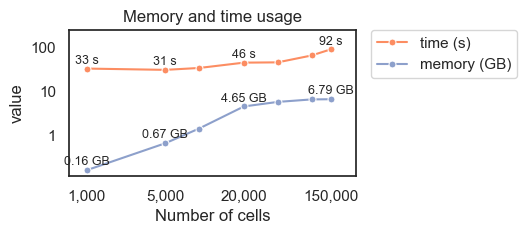

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.set_theme(style="white")
plt.figure(figsize=(5.5, 2.5))

colors = ["#FC8D62","#8DA0CB"]
# Both lineplots
ax = sns.lineplot(data=df_combined, x='n_cells', y='time_mean', marker='o', markersize=5, label='time (s)', color=colors[0])
ax = sns.lineplot(data=df_combined, x='n_cells', y='memory_mean', marker='o', markersize=5, label='memory (GB)', color=colors[1])

# Set logarithmic scale for both axes
plt.xscale('log')
plt.yscale('log')

# Print y values above each marker with an offset to avoid overlapping
for i in range(len(df_combined)):
    time_value = df_combined['time_mean'][i]
    memory_value = df_combined['memory_mean'][i]
    n_cells = df_combined['n_cells'][i]

    # Add an offset to the position of the text
    if n_cells in [1000, 5000, 25000, 147391]:
        ax.text(n_cells, time_value * 1.1, f"{int(time_value)} s", fontsize=9, ha='center', va='bottom')  # Time values
        ax.text(n_cells, memory_value * 1.1, f"{str(memory_value)[:4]} GB", fontsize=9, ha='center', va='bottom')  # Memory values

# Custom ticks and labels for the x and y axes
ax.set_xticks([1000,5000, 25000, 150000])
ax.set_yticks([1, 10, 100])
ax.set_xticklabels(['1,000','5,000', '20,000','150,000'])
ax.set_yticklabels(['1', '10', '100'])

# Set y-axis limits
ax.set_ylim(bottom=0, top=250)
ax.set_xlim(left=700, right=250000)

# Labels and layout
plt.xlabel('Number of cells')
plt.ylabel('value')
#title for the plot
plt.title('Memory and time usage')


# Move legend to the right
legend = plt.legend(loc='upper left', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

# legend labels
plt.tight_layout()
# save
plt.savefig('../figures/fig3a_rectangle_benchmark.pdf')

# Show the plot
plt.show()

## Figure 3B

In [20]:
runtimes_omni = pd.read_csv('../data/fig3/omnibench_runtime_data.csv', index_col=0)
runtimes_omni = runtimes_omni[runtimes_omni['bulk_samples'] == 5]
runtimes_omni = runtimes_omni[runtimes_omni['process'] == 'FULL WORKFLOW']
runtimes_omni = runtimes_omni[runtimes_omni['subset_value'] != 3000]

runtimes_rectangle['elapsed_minutes'] = runtimes_rectangle['time_mean'] / 60 # get minutes
runtimes_rectangle_omnibench = pd.read_csv('../data/fig3/rectangle_runtime_omnibench.csv')
runtimes_rectangle_omnibench = runtimes_rectangle_omnibench[runtimes_rectangle_omnibench['bulk_samples'] == 5]
runtimes_rectangle_omnibench = runtimes_rectangle_omnibench[runtimes_rectangle_omnibench['process'] == 'FULL WORKFLOW']
runtimes_rectangle_omnibench = runtimes_rectangle_omnibench[runtimes_rectangle_omnibench['subset_value'] != 3000]
#append rectangle omnibench rows to runtimes_omni
runtimes_omni = pd.concat([runtimes_omni, runtimes_rectangle_omnibench], ignore_index=True)
runtimes_omni.loc[runtimes_omni['method'] == 'Rectangle', 'method'] = 'Rectangle (deconvBench)'

In [21]:

for i, row in runtimes_rectangle.iterrows():
    n_cells = row['n_cells']
    runtime_rectangle = row['elapsed_minutes']
    runtimes_omni.loc[runtimes_omni['subset_value'] == n_cells, 'runtime_rectangle'] = runtime_rectangle


# round
runtimes_omni['n_cells'] = runtimes_omni['subset_value']



runtimes_omni['performance_ratio'] = runtimes_omni['elapsed_minutes'] / runtimes_omni['runtime_rectangle']

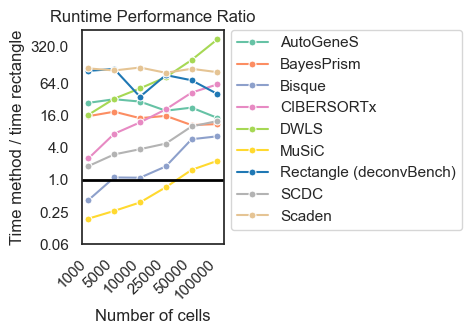

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter


method_palette = {
    "AutoGeneS": "#66C2A5",
    "BayesPrism": "#FC8D62",
    "Bisque": "#8DA0CB",
    "CIBERSORTx": "#E78AC3",
    "DWLS": "#A6D854",
    "MuSiC": "#FFD92F",
    "Rectangle (deconvBench)": "#1F78B4",
    "Scaden": "#E5C494",
    "SCDC": "#B3B3B3",

}
legend_order = sorted(list(method_palette.keys()))
# Filter and preprocess data
plot_runtime_df = runtimes_omni
plot_runtime_df['n_cells'] = plot_runtime_df['n_cells'].round(0).astype(int)
plot_runtime_df = plot_runtime_df.sort_values(by='n_cells')
plot_runtime_df['n_cells'] = plot_runtime_df['n_cells'].astype(str)
plot_runtime_df['performance_ratio'] = np.log(plot_runtime_df['performance_ratio'])

# Set style and figure size
sns.set_theme(style="white")
plt.figure(figsize=(5, 3.5))


# Create the line plot
ax = sns.lineplot(data=plot_runtime_df, x='n_cells', y='performance_ratio', hue='method', marker='o', markersize=5, palette=method_palette, hue_order=legend_order)
plt.xlabel('Number of cells')
plt.ylabel('Time method / time rectangle')
plt.title('Runtime Performance Ratio')

# Set y-axis to exponential values
def format_func(value, tick_number):
    return f'{np.round(np.exp(value), 2)}'

ax.yaxis.set_major_formatter(FuncFormatter(format_func))
plt.yticks([np.log(1/16), np.log(1/4), np.log(1), np.log(4), np.log(16), np.log(64), np.log(320)])  # Set the y-ticks


# Add horizontal line at y=1
plt.axhline(y=np.log(1), color='black', linestyle='-', linewidth=2)

# Rotate x-axis ticks
plt.xticks(rotation=45, ha='right')

# Move legend to the right and arrange in two columns
legend = plt.legend(loc='upper left', bbox_to_anchor=(1.05, 1), borderaxespad=0., ncol=1)

# Apply tight layout and save the plot
plt.tight_layout()
plt.savefig('../figures/fig3b_performance_ratio.pdf')
plt.show()

'

## Figure 3E

Load the data

In [6]:
annotations = pd.read_csv('../data/haoSub_annotations.csv', index_col=0)
genes = pd.read_csv('../data/haoSub_genes.csv', index_col=0)
counts = mmread('../data/haoSub_counts.mtx')
counts = pd.DataFrame(counts.todense())
counts = counts.T
counts.columns = genes['x']
adata_hao_sub = AnnData(counts, obs=annotations)

bulks_chen = pd.read_csv("../data/bulks_chen_tpm.csv", index_col=0)
bulks_peti = pd.read_csv("../data/bulks_petitprez_tpm.csv", index_col=0)
bulks_fino = pd.read_csv("../data/bulks_finotello_tpm.csv", index_col=0)
bulks_hoek = pd.read_csv("../data/bulks_hoek_tpm.csv", index_col=0)

sc_data_muris = pd.read_pickle("../data/sc_data_tabula_muris.pkl")
annotations = pd.read_csv("../data/annotations_tabula_muris.csv", index_col=0)
annotations = annotations['0']
annotations = pd.Series(annotations, index=sc_data_muris.columns)
adata_muris = AnnData(sc_data_muris.T, obs=annotations.to_frame(name="cell_type"))

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


For the standard Rectangle results we can take the results from figure 2

In [8]:
rectangle_fino_rmse, rectangle_fino_corr = 0.056, 0.906
rectangle_hoek_rmse, rectangle_hoek_corr = 0.071, 0.941
rectangle_chen_rmse, rectangle_chen_corr = 0.115, 0.836
rectangle_peti_rmse, rectangle_peti_corr = 0.144, 0.863

For the interventions we will create new results

First results without mRNA bias correction

In [ ]:
estimations_fino_no_bias, signature_results_fino_no_bias = rp.rectangle(adata_hao_sub, bulks_fino.T, correct_mrna_bias=False)
estimations_fino_no_bias.to_csv("../output/hao_estimations_fino_no_bias.csv")

hoek_estimations_no_bias, signature_results_hoek_no_bias = rp.rectangle(adata_hao_sub, bulks_hoek.T, correct_mrna_bias=False)
hoek_estimations_no_bias.to_csv("../output/hao_estimations_hoek_no_bias.csv")

chen_estimations_no_bias, signatures_chen_no_bias = rp.rectangle(adata_muris, bulks_chen.T, correct_mrna_bias=False)
chen_estimations_no_bias.to_csv("../output/muris_estimations_chen_no_bias.csv")

peti_estimations_no_bias, signatures_peti_no_bias = rp.rectangle(adata_muris, bulks_peti.T, correct_mrna_bias=False)
peti_estimations_no_bias.to_csv("../output/muris_estimations_peti_no_bias.csv")


In [12]:
finotello_gld = pd.read_csv('../data/finotello_facs.csv', index_col=0).T
finotello_gld = finotello_gld.fillna(0)
finotello_gld.columns = ["NK cells", 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophils', 'T cells CD8',
                         'T cells CD4 conv', 'Other']
finotello_gld = finotello_gld.T
hoek_gld = pd.read_csv('../data/hoek_facs.csv', index_col=0).T
hoek_gld = hoek_gld.fillna(0)
hoek_gld.columns = ["T cells", 'Monocytes', 'B cells', 'mDC', 'NK cells']
hoek_gld = hoek_gld.T

chen_gld = pd.read_csv('../data/chen_facs.csv', index_col=0).T
chen_gld = chen_gld.fillna(0)
chen_gld.columns = ["Monocytes", "B cells", 'T cells CD8', 'T cells CD4 Total']
petitprez_gld = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T
petitprez_gld = petitprez_gld.fillna(0)
petitprez_gld = petitprez_gld.fillna(0)
petitprez_gld.columns = ["T cells", 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                         'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                         'Granulocytes']
petitprez_gld = petitprez_gld.drop(['T cells'], axis=1)

In [19]:
gld_m_f_skip_bias, finotello_m_skip_bias = helper.match_dfs(finotello_gld, estimations_fino_no_bias.T)
evaluation_fintotello_skip_bias = helper.create_evaluation_df(gld_m_skip_bias, finotello_m_skip_bias)
rsme_finotello_skip_bias, r_finotello_skip_bias, p_finotello_skip_bias = helper.evaulate_total_df(
    evaluation_fintotello_skip_bias)

In [25]:
hoek_estimations_no_bias = pd.read_csv("../output/hao_estimations_hoek_no_bias.csv", index_col=0)
hoek_estimations_no_bias['T cells'] = hoek_estimations_no_bias['T cells CD4 conv'] + hoek_estimations_no_bias['T cells CD8'] + hoek_estimations_no_bias[
    'Tregs']
gld_m_h_skip_bias, hoek_m_skip_bias = helper.match_dfs(hoek_gld, hoek_estimations_no_bias.T)

evaluation_hoek_skip_bias = helper.create_evaluation_df(gld_m_h_skip_bias, hoek_m_skip_bias)
rsme_hoek_skip_bias, r_hoek_skip_bias, p_hoek_skip_bias = helper.evaulate_total_df(
    evaluation_hoek_skip_bias)

In [27]:
chen_estimations_no_bias = pd.read_csv("../output/muris_estimations_chen_no_bias.csv", index_col=0)
chen_estimations_no_bias['T cells CD4 Total'] = chen_estimations_no_bias['T cells CD4 conv'] + chen_estimations_no_bias['Tregs']
gld_m_c_skip_bias, chen_m_skip_bias = helper.match_dfs(chen_gld, chen_estimations_no_bias)

evaluation_chen_skip_bias = helper.create_evaluation_df(gld_m_c_skip_bias, chen_m_skip_bias)
rsme_chen_skip_bias, r_chen_skip_bias, p_chen_skip_bias = helper.evaulate_total_df(
    evaluation_chen_skip_bias)


In [28]:
peti_estimations_no_bias = pd.read_csv("../output/muris_estimations_peti_no_bias.csv", index_col=0)
gld_m_p_skip_bias, petitprez_m_skip_bias = helper.match_dfs(petitprez_gld, peti_estimations_no_bias)


evaluation_petitprez_skip_bias = helper.create_evaluation_df(gld_m_p_skip_bias, petitprez_m_skip_bias)
rsme_petitprez_skip_bias, r_petitprez_skip_bias, p_petitprez_skip_bias = helper.evaulate_total_df(
    evaluation_petitprez_skip_bias)

Second, results without Grid search

In [ ]:
estimations_fino_no_grid, signature_results_fino_no_grid = rp.rectangle(adata_hao_sub, bulks_fino.T, optimize_cutoffs=False)
estimations_fino_no_grid.to_csv("../output/hao_estimations_fino_no_grid.csv")
hoek_estimations_no_grid, signature_results_hoek_no_grid = rp.rectangle(adata_hao_sub, bulks_hoek.T, optimize_cutoffs=False)
hoek_estimations_no_grid.to_csv("../output/hao_estimations_hoek_no_grid.csv")
chen_estimations_no_grid, signatures_chen_no_grid = rp.rectangle(adata_muris, bulks_chen.T, optimize_cutoffs=False)
chen_estimations_no_grid.to_csv("../output/muris_estimations_chen_no_grid.csv")
peti_estimations_no_grid, signatures_peti_no_grid = rp.rectangle(adata_muris, bulks_peti.T, optimize_cutoffs=False)
peti_estimations_no_grid.to_csv("../output/muris_estimations_peti_no_grid.csv")

In [31]:
gld_m_f_skip_grid, finotello_m_skip_grid = helper.match_dfs(finotello_gld, estimations_fino_no_grid.T)
evaluation_fintotello_skip_grid = helper.create_evaluation_df(gld_m_f_skip_grid, finotello_m_skip_grid)
rsme_finotello_skip_grid, r_finotello_skip_grid, p_finotello_skip_grid = helper.evaulate_total_df(
    evaluation_fintotello_skip_grid)


In [33]:
hoek_estimations_no_grid = pd.read_csv("../output/hao_estimations_hoek_no_grid.csv", index_col=0)
hoek_estimations_no_grid['T cells'] = hoek_estimations_no_grid['T cells CD4 conv'] + hoek_estimations_no_grid['T cells CD8'] + hoek_estimations_no_grid[
    'Tregs']
gld_m_h_skip_grid, hoek_m_skip_grid = helper.match_dfs(hoek_gld, hoek_estimations_no_grid.T)
evaluation_hoek_skip_grid = helper.create_evaluation_df(gld_m_h_skip_grid, hoek_m_skip_grid)
rsme_hoek_skip_grid, r_hoek_skip_grid, p_hoek_skip_grid = helper.evaulate_total_df(
    evaluation_hoek_skip_grid)


In [34]:
chen_estimations_no_grid = pd.read_csv("../output/muris_estimations_chen_no_grid.csv", index_col=0)
chen_estimations_no_grid['T cells CD4 Total'] = chen_estimations_no_grid['T cells CD4 conv'] + chen_estimations_no_grid['Tregs']
gld_m_c_skip_grid, chen_m_skip_grid = helper.match_dfs(chen_gld, chen_estimations_no_grid)
evaluation_chen_skip_grid = helper.create_evaluation_df(gld_m_c_skip_grid, chen_m_skip_grid)
rsme_chen_skip_grid, r_chen_skip_grid, p_chen_skip_grid = helper.evaulate_total_df(
    evaluation_chen_skip_grid)

In [35]:
peti_estimations_no_grid = pd.read_csv("../output/muris_estimations_peti_no_grid.csv", index_col=0)
gld_m_p_skip_grid, petitprez_m_skip_grid = helper.match_dfs(petitprez_gld, peti_estimations_no_grid)
evaluation_petitprez_skip_grid = helper.create_evaluation_df(gld_m_p_skip_grid, petitprez_m_skip_grid)
rsme_petitprez_skip_grid, r_petitprez_skip_grid, p_petitprez_skip_grid = helper.evaulate_total_df(
    evaluation_petitprez_skip_grid)


To see what the estimations look like without the unknown content correction, we can remove the unknown content from the estimations and normalize the results to 1

In [57]:
estimations_fino = pd.read_csv("../output/hao_estimations_fino_sub.csv", index_col=0)
estimations_finon_no_unknown = estimations_fino.drop('Unknown', axis=1)
estimations_finon_no_unknown = estimations_finon_no_unknown.div(estimations_finon_no_unknown.sum(axis=1), axis=0)
estimations_finon_no_unknown.to_csv("../output/hao_estimations_fino_no_unknown.csv")


In [56]:
estimations_hoek = pd.read_csv("../output/hao_estimations_hoek_sub.csv", index_col=0)
estimations_hoek_no_unknown = estimations_hoek.drop('Unknown', axis=1)
estimations_hoek_no_unknown = estimations_hoek_no_unknown.div(estimations_hoek_no_unknown.sum(axis=1), axis=0)
estimations_hoek_no_unknown.to_csv("../output/hao_estimations_hoek_no_unknown.csv")

In [60]:
estimations_chen = pd.read_csv("../output/muris_estimations_chen.csv", index_col=0)
estimations_chen_no_unknown = estimations_chen.drop('Unknown', axis=1)
estimations_chen_no_unknown = estimations_chen_no_unknown.div(estimations_chen_no_unknown.sum(axis=1), axis=0)
estimations_chen_no_unknown.to_csv("../output/muris_estimations_chen_no_unknown.csv")

In [65]:
estimations_peti = pd.read_csv("../output/muris_estimations_peti.csv", index_col=0)
estimations_peti_no_unknown = estimations_peti.drop('Unknown', axis=1)
estimations_peti_no_unknown = estimations_peti_no_unknown.div(estimations_peti_no_unknown.sum(axis=1), axis=0)
estimations_peti_no_unknown.to_csv("../output/muris_estimations_peti_no_unknown.csv")


In [54]:
gld_m_f_no_unknown, finotello_m_no_unknown = helper.match_dfs(finotello_gld, estimations_finon_no_unknown.T)
evaluation_fintotello_no_unknown = helper.create_evaluation_df(gld_m_f_no_unknown, finotello_m_no_unknown)
rsme_finotello_no_unknown, r_finotello_no_unknown, p_finotello_no_unknown = helper.evaulate_total_df(
    evaluation_fintotello_no_unknown)


In [61]:
hoek_estimations_no_unknown = pd.read_csv("../output/hao_estimations_hoek_no_unknown.csv", index_col=0)
hoek_estimations_no_unknown['T cells'] = hoek_estimations_no_unknown['T cells CD4 conv'] + hoek_estimations_no_unknown['T cells CD8'] + hoek_estimations_no_unknown[
    'Tregs']
gld_m_h_no_unknown, hoek_m_no_unknown = helper.match_dfs(hoek_gld, hoek_estimations_no_unknown.T)
evaluation_hoek_no_unknown = helper.create_evaluation_df(gld_m_h_no_unknown, hoek_m_no_unknown)
rsme_hoek_no_unknown, r_hoek_no_unknown, p_hoek_no_unknown = helper.evaulate_total_df(
    evaluation_hoek_no_unknown)


In [62]:
chen_estimations_no_unknown = pd.read_csv("../output/muris_estimations_chen_no_unknown.csv", index_col=0)
chen_estimations_no_unknown['T cells CD4 Total'] = chen_estimations_no_unknown['T cells CD4 conv'] + chen_estimations_no_unknown['Tregs']
gld_m_c_no_unknown, chen_m_no_unknown = helper.match_dfs(chen_gld, chen_estimations_no_unknown)
evaluation_chen_no_unknown = helper.create_evaluation_df(gld_m_c_no_unknown, chen_m_no_unknown)
rsme_chen_no_unknown, r_chen_no_unknown, p_chen_no_unknown = helper.evaulate_total_df(
    evaluation_chen_no_unknown)

In [66]:
peti_estimations_no_unknown = pd.read_csv("../output/muris_estimations_peti_no_unknown.csv", index_col=0)
gld_m_p_no_unknown, petitprez_m_no_unknown = helper.match_dfs(petitprez_gld, peti_estimations_no_unknown)
evaluation_petitprez_no_unknown = helper.create_evaluation_df(gld_m_p_no_unknown, petitprez_m_no_unknown)
rsme_petitprez_no_unknown, r_petitprez_no_unknown, p_petitprez_no_unknown = helper.evaulate_total_df(
    evaluation_petitprez_no_unknown)

Rectangle does not allow to skip the hierarchical deconvolution step, but we ca run the 2-step deconvolution and modify the clustered results so that hierachical deconvolution can not be applied.



In [ ]:
signature_result_fino = rp.pp.build_rectangle_signatures(adata_hao_sub,bulks=bulks_fino.T)
marker_genes_per_cell_type = signature_result_fino.marker_genes_per_cell_type
for key in marker_genes_per_cell_type.keys():
    marker_genes_per_cell_type[key] = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j',
                                       'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't']
signature_result_fino.marker_genes_per_cell_type = marker_genes_per_cell_type

estimations_fino_no_hierarchy, _ = rp.tl.deconvolution(signature_result_fino,bulks_fino.T)
estimations_fino_no_hierarchy.to_csv("../output/hao_estimations_fino_no_hierarchy.csv")



In [ ]:
signature_result_hoek = rp.pp.build_rectangle_signatures(adata_hao_sub,bulks=bulks_hoek.T)
marker_genes_per_cell_type = signature_result_hoek.marker_genes_per_cell_type
for key in marker_genes_per_cell_type.keys():
    marker_genes_per_cell_type[key] = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j',
                                       'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't']
signature_result_hoek.marker_genes_per_cell_type = marker_genes_per_cell_type
hoek_estimations_no_hierarchy, _ = rp.tl.deconvolution(signature_result_hoek,bulks_hoek.T)
hoek_estimations_no_hierarchy.to_csv("../output/hao_estimations_hoek_no_hierarchy.csv")

In [ ]:
signature_result_chen = rp.pp.build_rectangle_signatures(adata_muris,bulks=bulks_chen.T)
marker_genes_per_cell_type = signature_result_chen.marker_genes_per_cell_type
for key in marker_genes_per_cell_type.keys():
    marker_genes_per_cell_type[key] = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j',
                                       'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't']
signature_result_chen.marker_genes_per_cell_type = marker_genes_per_cell_type
chen_estimations_no_hierarchy, _ = rp.tl.deconvolution(signature_result_chen,bulks=bulks_chen.T)
chen_estimations_no_hierarchy.to_csv("../output/muris_estimations_chen_no_hierarchy.csv")


In [ ]:
signature_result_peti = rp.pp.build_rectangle_signatures(adata_muris,bulks=bulks_peti.T)
marker_genes_per_cell_type = signature_result_peti.marker_genes_per_cell_type
for key in marker_genes_per_cell_type.keys():
    marker_genes_per_cell_type[key] = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j',
                                       'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't']
signature_result_peti.marker_genes_per_cell_type = marker_genes_per_cell_type
peti_estimations_no_hierarchy, _ = rp.tl.deconvolution(signature_result_peti,bulks=bulks_peti.T)
peti_estimations_no_hierarchy.to_csv("../output/muris_estimations_peti_no_hierarchy.csv")

In [75]:
gld_m_f_no_hierarchy, finotello_m_no_hierarchy = helper.match_dfs(finotello_gld, estimations_fino_no_hierarchy.T)
evaluation_fintotello_no_hierarchy = helper.create_evaluation_df(gld_m_f_no_hierarchy, finotello_m_no_hierarchy)
rsme_finotello_no_hierarchy, r_finotello_no_hierarchy, p_finotello_no_hierarchy = helper.evaulate_total_df(
    evaluation_fintotello_no_hierarchy)


In [79]:
estimations_hoek_no_hierarchy = pd.read_csv("../output/hao_estimations_hoek_no_hierarchy.csv", index_col=0)
hoek_estimations_no_hierarchy['T cells'] = hoek_estimations_no_hierarchy['T cells CD4 conv'] + hoek_estimations_no_hierarchy['T cells CD8'] + hoek_estimations_no_hierarchy[
    'Tregs']
gld_m_h_no_hierarchy, hoek_m_no_hierarchy = helper.match_dfs(hoek_gld, hoek_estimations_no_hierarchy.T)
evaluation_hoek_no_hierarchy = helper.create_evaluation_df(gld_m_h_no_hierarchy, hoek_m_no_hierarchy)
rsme_hoek_no_hierarchy, r_hoek_no_hierarchy, p_hoek_no_hierarchy = helper.evaulate_total_df(
    evaluation_hoek_no_hierarchy)


In [80]:
estimations_chen_no_hierarchy = pd.read_csv("../output/muris_estimations_chen_no_hierarchy.csv", index_col=0)
chen_estimations_no_hierarchy['T cells CD4 Total'] = chen_estimations_no_hierarchy['T cells CD4 conv'] + chen_estimations_no_hierarchy['Tregs']
gld_m_c_no_hierarchy, chen_m_no_hierarchy = helper.match_dfs(chen_gld, chen_estimations_no_hierarchy)
evaluation_chen_no_hierarchy = helper.create_evaluation_df(gld_m_c_no_hierarchy, chen_m_no_hierarchy)
rsme_chen_no_hierarchy, r_chen_no_hierarchy, p_chen_no_hierarchy = helper.evaulate_total_df(
    evaluation_chen_no_hierarchy)

In [83]:
estimations_peti_no_hierarchy = pd.read_csv("../output/muris_estimations_peti_no_hierarchy.csv", index_col=0)
gld_m_p_no_hierarchy, petitprez_m_no_hierarchy = helper.match_dfs(petitprez_gld, peti_estimations_no_hierarchy)
evaluation_petitprez_no_hierarchy = helper.create_evaluation_df(gld_m_p_no_hierarchy, petitprez_m_no_hierarchy)
rsme_petitprez_no_hierarchy, r_petitprez_no_hierarchy, p_petitprez_no_hierarchy = helper.evaulate_total_df(
    evaluation_petitprez_no_hierarchy)

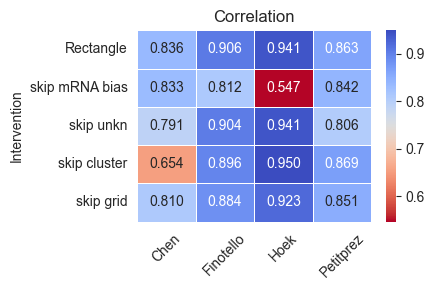

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
sns.set_style("white")

# Values and categories
values = [rectangle_hoek_corr, r_hoek_skip_bias, r_hoek_no_unknown, r_hoek_no_hierarchy, r_hoek_skip_grid]
interventions = ['Rectangle', 'skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


# Create DataFrame
df = pd.DataFrame({'Intervention': interventions, 'Delta': values})
df['Set'] = 'hoek'

values_f = [rectangle_fino_corr,  r_finotello_skip_bias, r_finotello_no_unknown, r_finotello_no_hierarchy, r_finotello_skip_grid]
interventions_f =  ['Rectangle', 'skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_f = pd.DataFrame({'Intervention': interventions_f, 'Delta': values_f})
df_f['Set'] = 'finotello'

values_c = [rectangle_chen_corr, r_chen_skip_bias, r_chen_no_unknown, r_chen_no_hierarchy, r_chen_skip_grid]
interventions_c = ['Rectangle', 'skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_c = pd.DataFrame({'Intervention': interventions_c, 'Delta': values_c})
df_c['Set'] = 'chen'

values_p = [rectangle_peti_corr, r_petitprez_skip_bias, r_petitprez_no_unknown, r_petitprez_no_hierarchy, r_petitprez_skip_grid]
interventions_p = ['Rectangle', 'skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_p = pd.DataFrame({'Intervention': interventions_p, 'Delta': values_p})
df_p['Set'] = 'petitprez'

df_corr_int  =  df_c['Delta'].to_frame()
df_corr_int['Chen'] = df_c['Delta']
df_corr_int['Finotello'] = df_f['Delta']
df_corr_int['Hoek'] = df['Delta']
df_corr_int['Petitprez'] = df_p['Delta']

df_corr_int['Intervention'] = df['Intervention']
df_corr_int = df_corr_int.drop('Delta', axis=1)


plt.figure(figsize=(4.5, 3))
sns.heatmap(df_corr_int.set_index('Intervention'), annot=True, cmap='coolwarm_r', fmt=".3f", linewidths=.5)
plt.title("Correlation")
# 90 degree rotation of x-axis labels
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('../figures/fig3c3e_corr_int_heatmap.pdf')



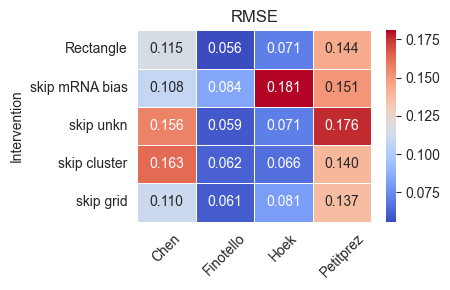

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_style("white")

palette = sns.color_palette('deep')[:4]
first_three_hex_colors = ['#%02x%02x%02x' % (int(color[0]*255), int(color[1]*255), int(color[2]*255)) for color in palette]

# Values and categories
values = [rectangle_hoek_rmse, rsme_hoek_skip_bias, rsme_hoek_no_unknown, rsme_hoek_no_hierarchy, rsme_hoek_skip_grid]
interventions =  ['Rectangle','skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


# Create DataFrame
df = pd.DataFrame({'Intervention': interventions, 'Delta': values})
df['Set'] = 'hoek'

values_f = [rectangle_fino_rmse, rsme_finotello_skip_bias, rsme_finotello_no_unknown, rsme_finotello_no_hierarchy, rsme_finotello_skip_grid]
interventions_f =  ['Rectangle','skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_f = pd.DataFrame({'Intervention': interventions_f, 'Delta': values_f})
df_f['Set'] = 'finotello'

values_c = [rectangle_chen_rmse, rsme_chen_skip_bias, rsme_chen_no_unknown, rsme_chen_no_hierarchy, rsme_chen_skip_grid]
interventions_c = ['Rectangle','skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_c = pd.DataFrame({'Intervention': interventions_c, 'Delta': values_c})
df_c['Set'] = 'chen'

values_p = [rectangle_peti_rmse, rsme_petitprez_skip_bias, rsme_petitprez_no_unknown, rsme_petitprez_no_hierarchy, rsme_petitprez_skip_grid]
interventions_p = ['Rectangle','skip mRNA bias', "skip unkn", "skip cluster", "skip grid"]


df_p = pd.DataFrame({'Intervention': interventions_p, 'Delta': values_p})
df_p['Set'] = 'petitprez'

df_rsme_int  =  df_c['Delta'].to_frame()
df_rsme_int['Chen'] = df_c['Delta']
df_rsme_int['Finotello'] = df_f['Delta']
df_rsme_int['Hoek'] = df['Delta']
df_rsme_int['Petitprez'] = df_p['Delta']

df_rsme_int['Intervention'] = df['Intervention']
df_rsme_int = df_rsme_int.drop('Delta', axis=1)


plt.figure(figsize=(4.5, 3))
sns.heatmap(df_rsme_int.set_index('Intervention'), annot=True, cmap='coolwarm', fmt=".3f", linewidths=.5)
plt.title("RMSE")
# 90 degree rotation of x-axis labels
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('../figures/fig3c3e_rmse_int_heatmap.pdf')






# 3D

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the spatial data
spatial_df = pd.read_csv('../data/fig3/spatial_total.csv', index_col=0)
spatial_df = spatial_df.drop('Total', axis=1)

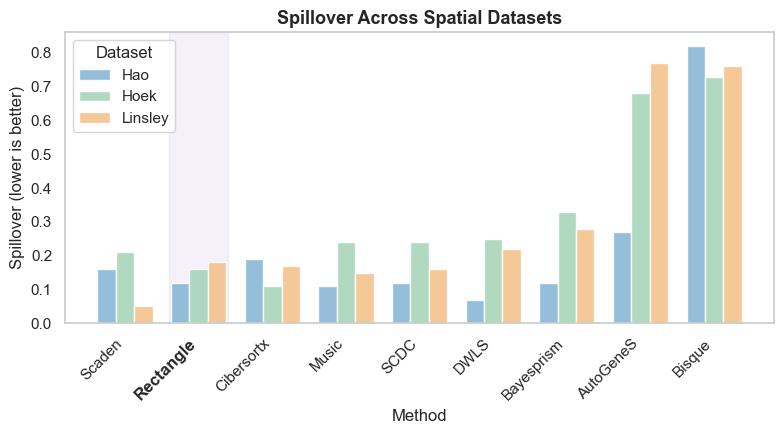


Spillover Summary:
             Hao  Hoek  Linsley
Method                         
Scaden      0.16  0.21     0.05
Rectangle   0.12  0.16     0.18
Cibersortx  0.19  0.11     0.17
Music       0.11  0.24     0.15
SCDC        0.12  0.24     0.16
DWLS        0.07  0.25     0.22
Bayesprism  0.12  0.33     0.28
AutoGeneS   0.27  0.68     0.77
Bisque      0.82  0.73     0.76

Mean spillover per method:
Method
Scaden        0.140
Rectangle     0.153
Cibersortx    0.157
Music         0.167
SCDC          0.173
DWLS          0.180
Bayesprism    0.243
AutoGeneS     0.573
Bisque        0.770
dtype: float64


In [37]:

# Sort by the mean performance across datasets (lower is better)
spatial_df['Mean'] = spatial_df[['Hao', 'Hoek', 'Linsley']].mean(axis=1)
spatial_df = spatial_df.sort_values('Mean')
spatial_df = spatial_df.drop('Mean', axis=1)

# Create figure
fig, ax = plt.subplots(figsize=(8, 4.5))

# Grouped bar chart
datasets = ['Hao', 'Hoek', 'Linsley']
methods = spatial_df.index.tolist()
x = np.arange(len(methods))
width = 0.25

# Soft, eye-friendly color palette
colors = ['#88B7D5', '#A8D5BA', '#F4C28C']

for i, dataset in enumerate(datasets):
    offset = width * (i - 1)
    bars = ax.bar(x + offset, spatial_df[dataset], width, label=dataset, color=colors[i], alpha=0.9)

# Highlight Rectangle with a vertical span and bold x-label
if 'Rectangle' in methods:
    rect_idx = methods.index('Rectangle')
    ax.axvspan(rect_idx - 0.4, rect_idx + 0.4, alpha=0.15, color='#B8A4D9', zorder=0)

    # Make Rectangle label bold
    labels = ax.get_xticklabels()
    labels[rect_idx].set_weight('bold')
    labels[rect_idx].set_fontsize(12)

ax.set_xlabel('Method', fontsize=12)
ax.set_ylabel('Spillover (lower is better)', fontsize=12)
ax.set_title('Spillover Across Spatial Datasets', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=45, ha='right')
ax.legend(title='Dataset', loc='upper left')
# Remove grid lines
ax.grid(False)

plt.tight_layout()
plt.savefig('../figures/fig3d_spatial_spillover.pdf', dpi=300, bbox_inches='tight')
plt.show()

print("\nSpillover Summary:")
print(spatial_df.round(3))
print("\nMean spillover per method:")
print(spatial_df.mean(axis=1).round(3).sort_values())
